In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px 
import plotly.io as pio 
pio.renderers.default = "svg" 

In [3]:
raw_df = pd.read_csv("Zomato Chennai Listing 2020.csv") 

In [4]:
raw_df.head()

,Zomato URL,Name of Restaurant,Address,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features
0,https://www.zomato.com/chennai/yaa-mohaideen-b...,Yaa Mohaideen Briyani,"336 & 338, Main Road, Pallavaram, Chennai",Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500.0,4.3,1500,4.3,9306,"['Home Delivery', 'Indoor Seating']"
1,https://www.zomato.com/chennai/sukkubhai-biriy...,Sukkubhai Biriyani,"New 14, Old 11/3Q, Railway Station Road, MKN ...",Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000.0,4.4,3059,4.1,39200,"['Home Delivery', 'Free Parking', 'Table booki..."
2,https://www.zomato.com/chennai/ss-hyderabad-bi...,SS Hyderabad Biryani,"98/339, Arcot Road, Opposite Gokulam Chit Fun...",Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500.0,4.3,1361,4.4,10500,"['Home Delivery', 'Indoor Seating']"
3,https://www.zomato.com/chennai/kfc-perambur,KFC,"10, Periyar Nagar, 70 Feet Road, Near Sheeba ...",Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500.0,4.0,1101,4.0,11200,"['Home Delivery', 'Free Parking', 'Card Upon D..."
4,https://www.zomato.com/chennai/tasty-kitchen-p...,Tasty Kitchen,"135B, SRP Colony, Peravallur, Near Perambur, ...",Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450.0,4.2,617,4.1,22400,"['Home Delivery', 'Indoor Seating']"


In [5]:
raw_df.shape

(12032, 12)

In [6]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12032 entries, 0 to 12031
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Zomato URL             12032 non-null  str    
 1   Name of Restaurant     12032 non-null  str    
 2   Address                12032 non-null  str    
 3   Location               12032 non-null  str    
 4   Cuisine                12032 non-null  str    
 5   Top Dishes             12032 non-null  str    
 6   Price for 2            12032 non-null  float64
 7   Dining Rating          6681 non-null   float64
 8   Dining Rating Count    11812 non-null  str    
 9   Delivery Rating        6181 non-null   float64
 10  Delivery Rating Count  11812 non-null  str    
 11  Features               12032 non-null  str    
dtypes: float64(3), str(9)
memory usage: 1.1 MB


In [7]:
raw_df.describe()

,Price for 2,Dining Rating,Delivery Rating
count,12032.000000,6681.000000,6181.000000
mean,397.611370,3.387756,3.805290
std,332.045938,0.558181,0.374213
min,40.000000,0.300000,0.300000
25%,200.000000,3.100000,3.600000
50%,300.000000,3.500000,3.900000
75%,450.000000,3.800000,4.000000
max,5000.000000,4.900000,4.700000


In [8]:
#. Find Null Values
raw_df.isnull().sum()

Zomato URL                  0
Name of Restaurant          0
Address                     0
Location                    0
Cuisine                     0
Top Dishes                  0
Price for 2                 0
Dining Rating            5351
Dining Rating Count       220
Delivery Rating          5851
Delivery Rating Count     220
Features                    0
dtype: int64

In [9]:
# Dropping columns which are not required for further analysis 
 
raw_df.drop(['Zomato URL','Address'], axis=1, inplace=True) 
raw_df.head()

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500.0,4.3,1500,4.3,9306,"['Home Delivery', 'Indoor Seating']"
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000.0,4.4,3059,4.1,39200,"['Home Delivery', 'Free Parking', 'Table booki..."
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500.0,4.3,1361,4.4,10500,"['Home Delivery', 'Indoor Seating']"
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500.0,4.0,1101,4.0,11200,"['Home Delivery', 'Free Parking', 'Card Upon D..."
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450.0,4.2,617,4.1,22400,"['Home Delivery', 'Indoor Seating']"


In [10]:
#. Checking Duplicate Records

temp = raw_df['Name of Restaurant'] == 'Name of Restaurant'
dataset_dup = raw_df[temp]
dataset_dup

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features


In [11]:
raw_df.isnull().sum()

Name of Restaurant          0
Location                    0
Cuisine                     0
Top Dishes                  0
Price for 2                 0
Dining Rating            5351
Dining Rating Count       220
Delivery Rating          5851
Delivery Rating Count     220
Features                    0
dtype: int64

In [12]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12032 entries, 0 to 12031
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Name of Restaurant     12032 non-null  str    
 1   Location               12032 non-null  str    
 2   Cuisine                12032 non-null  str    
 3   Top Dishes             12032 non-null  str    
 4   Price for 2            12032 non-null  float64
 5   Dining Rating          6681 non-null   float64
 6   Dining Rating Count    11812 non-null  str    
 7   Delivery Rating        6181 non-null   float64
 8   Delivery Rating Count  11812 non-null  str    
 9   Features               12032 non-null  str    
dtypes: float64(3), str(7)
memory usage: 940.1 KB


In [13]:
raw_df["Dining Rating"].value_counts()

Dining Rating
3.6    584
3.5    553
3.7    525
3.4    500
3.3    463
3.8    460
3.2    433
3.9    379
3.1    363
2.0    354
3.0    302
4.0    288
2.9    257
4.1    221
2.8    192
4.2    142
2.7    138
4.3    105
2.6     99
2.5     71
4.4     61
2.4     46
4.5     36
2.3     32
2.2     20
4.6     17
4.7     12
2.1     10
4.9      7
4.8      4
1.9      3
1.7      2
0.3      1
1.0      1
Name: count, dtype: int64

In [14]:
raw_df["Dining Rating"].unique()

array([4.3, 4.4, 4. , 4.2, 4.1, nan, 3.9, 4.5, 4.7, 3.5, 4.6, 3.6, 3.8,
       4.9, 4.8, 3.7, 2.7, 2.9, 2.6, 3. , 3.4, 2.4, 3.3, 2.8, 2.1, 2. ,
       2.2, 3.2, 2.5, 3.1, 2.3, 1.9, 1.7, 0.3, 1. ])

In [15]:
raw_df['Dining Rating Count'].value_counts()

Dining Rating Count
Does not offer Dining        2603
Not enough Dining Reviews    2528
4                             339
5                             271
6                             248
                             ... 
858                             1
477                             1
388                             1
253                             1
224                             1
Name: count, Length: 793, dtype: int64

In [16]:
raw_df["Dining Rating Count"] = raw_df["Dining Rating Count"].replace(to_replace=["Does not offer Dining","NA","Not enough Dining Reviews"],value = 0)
raw_df["Dining Rating Count"] = pd.Series(raw_df["Dining Rating Count"])
raw_df["Dining Rating Count"] = pd.to_numeric(raw_df["Dining Rating Count"], errors="coerce")
raw_df["Dining Rating Count"] = raw_df["Dining Rating Count"].fillna(0).astype(int)

In [17]:
raw_df["Dining Rating"] = pd.Series(raw_df["Dining Rating"])
raw_df["Dining Rating"] = pd.to_numeric(raw_df["Dining Rating"], errors="coerce")
raw_df["Dining Rating"] = raw_df["Dining Rating"].fillna(0).astype(int)

In [18]:
raw_df["Delivery Rating Count"] = pd.Series(raw_df["Delivery Rating Count"])
raw_df["Delivery Rating Count"] = pd.to_numeric(raw_df["Delivery Rating Count"], errors="coerce")
raw_df["Delivery Rating Count"] = raw_df["Delivery Rating Count"].fillna(0).astype(float)

In [19]:
raw_df['Delivery Rating'] = raw_df['Delivery Rating'].fillna(0)

In [20]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12032 entries, 0 to 12031
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Name of Restaurant     12032 non-null  str    
 1   Location               12032 non-null  str    
 2   Cuisine                12032 non-null  str    
 3   Top Dishes             12032 non-null  str    
 4   Price for 2            12032 non-null  float64
 5   Dining Rating          12032 non-null  int64  
 6   Dining Rating Count    12032 non-null  int64  
 7   Delivery Rating        12032 non-null  float64
 8   Delivery Rating Count  12032 non-null  float64
 9   Features               12032 non-null  str    
dtypes: float64(3), int64(2), str(5)
memory usage: 940.1 KB


In [21]:
raw_df.head()

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500.0,4,1500,4.3,9306.0,"['Home Delivery', 'Indoor Seating']"
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000.0,4,3059,4.1,39200.0,"['Home Delivery', 'Free Parking', 'Table booki..."
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500.0,4,1361,4.4,10500.0,"['Home Delivery', 'Indoor Seating']"
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500.0,4,1101,4.0,11200.0,"['Home Delivery', 'Free Parking', 'Card Upon D..."
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450.0,4,617,4.1,22400.0,"['Home Delivery', 'Indoor Seating']"


In [22]:
# NA convert to '0'
raw_df["Top Dishes"].fillna(0)

0        ['Bread Halwa', ' Chicken 65', ' Mutton Biryan...
1        ['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...
2        ['Brinjal Curry', ' Tandoori Chicken', ' Chick...
3                                        ['Zinger Burger']
4        ['Mutton Biryani', ' Chicken Rice', ' Tomato R...
                               ...                        
12027                                              Invalid
12028                                              Invalid
12029                                              Invalid
12030                                              Invalid
12031                                              Invalid
Name: Top Dishes, Length: 12032, dtype: str

In [23]:
raw_df["Top Dishes"] = raw_df["Top Dishes"].replace(to_replace = ["Invalid"],value="Uncategorized Dish")

In [24]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12032 entries, 0 to 12031
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Name of Restaurant     12032 non-null  str    
 1   Location               12032 non-null  str    
 2   Cuisine                12032 non-null  str    
 3   Top Dishes             12032 non-null  str    
 4   Price for 2            12032 non-null  float64
 5   Dining Rating          12032 non-null  int64  
 6   Dining Rating Count    12032 non-null  int64  
 7   Delivery Rating        12032 non-null  float64
 8   Delivery Rating Count  12032 non-null  float64
 9   Features               12032 non-null  str    
dtypes: float64(3), int64(2), str(5)
memory usage: 940.1 KB


In [25]:
#. Change the datatype after a clean Record
raw_df["Name of Restaurant"] = raw_df["Name of Restaurant"].astype(object)
raw_df["Location"] = raw_df["Location"].astype(object)
raw_df["Cuisine"] = raw_df["Cuisine"].astype(object)
raw_df["Top Dishes"] = raw_df["Top Dishes"].astype(object)
raw_df["Price for 2"] = raw_df["Price for 2"].astype("int")
raw_df["Dining Rating"] = raw_df["Dining Rating"].astype("int")
raw_df["Dining Rating Count"] = raw_df["Dining Rating Count"].astype("float64")
raw_df["Delivery Rating"] = raw_df["Delivery Rating"].astype("int")
raw_df["Delivery Rating Count"] = raw_df["Delivery Rating Count"].astype("float64")
raw_df["Features"] = raw_df["Features"].astype(object)

In [26]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12032 entries, 0 to 12031
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Name of Restaurant     12032 non-null  object 
 1   Location               12032 non-null  object 
 2   Cuisine                12032 non-null  object 
 3   Top Dishes             12032 non-null  object 
 4   Price for 2            12032 non-null  int64  
 5   Dining Rating          12032 non-null  int64  
 6   Dining Rating Count    12032 non-null  float64
 7   Delivery Rating        12032 non-null  int64  
 8   Delivery Rating Count  12032 non-null  float64
 9   Features               12032 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 940.1+ KB


In [27]:
unwanted_dining_dataset = (raw_df["Dining Rating"] == 0)
raw_df[unwanted_dining_dataset]

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features
6,Bai Veetu Kalyanam,Navallur,['Biryani'],"['Bread Halwa', ' Mutton Biryani', ' Brinjal G...",350,0,0.0,4,1061.0,['Home Delivery']
77,Al Dhareeq Beef Biriyani,Kodambakkam,['Biryani'],['Beef Biryani'],300,0,0.0,3,19600.0,['Home Delivery']
106,Twilight Take Out,Nungambakkam,"['North Indian', ' Chinese', ' Rolls', ' Conti...","['Club Sandwich', ' Chicken Tikka Roll', ' Chi...",350,0,0.0,4,11200.0,"['Home Delivery', 'Free Parking']"
107,The Red Box,Anna Nagar West,['Chinese'],"['Noodle', ' Chilli Chicken Gravy', ' Dragon C...",200,0,0.0,4,11500.0,['Home Delivery']
114,Charminar Biriyani Centre,Royapettah,"['Biryani', ' North Indian']","['Chicken Biryani', ' Bread Halwa', ' Brinjal ...",300,0,0.0,3,652.0,"['Home Delivery', 'Standing Tables']"
...,...,...,...,...,...,...,...,...,...,...
12027,CK's Sandwiches,Porur,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"
12028,CK's Sandwiches,Kolathur,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"
12029,CK's Sandwiches,Anna Nagar East,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"
12030,CK's Sandwiches,Ramapuram,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"


In [28]:
unwanted_delivery_dataset = (raw_df["Delivery Rating"] == 0)
raw_df[unwanted_delivery_dataset]

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features
15,Welcome Hotel,Purasavakkam,"['South Indian', ' Desserts', ' Beverages']","['Pongal', ' Podi Dosa', ' Idli Sambar', ' Vad...",300,4,1094.0,0,0.0,"['Breakfast', 'Vegetarian Only', 'Indoor Seati..."
18,Wire Room Bar & Kitchen,"Phoenix Market City, Velachery","['Continental', ' Asian']","['Cocktails', ' Salad', ' Beer', ' Tikka', ' P...",2000,4,354.0,0,0.0,"['Full Bar Available', 'Mall Parking', 'Dance ..."
23,BFF 2.0,RA Puram,"['North Indian', ' Continental', ' Italian']","['Crispy Chicken', ' Cocktails', ' Pizza', ' N...",1500,4,464.0,0,0.0,"['Full Bar Available', 'Indoor Seating', 'Nigh..."
85,Bazaar - All Day Diner - Grand by GRT Hotels,Grand by GRT Hotels,"['North Indian', ' South Indian', ' Continenta...","['Pizza', ' Pasta', ' Fish', ' Chaat', ' Momos...",2500,4,1198.0,0,0.0,"['Breakfast', 'Home Delivery', 'Serves Alcohol..."
89,Coal Barbecues,Velachery,"['North Indian', ' Chinese']","['Chicken Honey', ' Fish', ' Prawn', ' Waffles...",1400,4,9410.0,0,0.0,"['Indoor Seating', 'Buffet', 'Table reservatio..."
...,...,...,...,...,...,...,...,...,...,...
12027,CK's Sandwiches,Porur,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"
12028,CK's Sandwiches,Kolathur,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"
12029,CK's Sandwiches,Anna Nagar East,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"
12030,CK's Sandwiches,Ramapuram,['Sandwich'],Uncategorized Dish,350,0,0.0,0,0.0,"['Breakfast', 'Delivery Only']"


In [29]:
dataset_unwanted_dining_dataset = raw_df[~unwanted_dining_dataset]

In [30]:
dataset_unwanted_delivery_dataset = raw_df[~unwanted_delivery_dataset]

In [31]:
raw_df = pd.merge(dataset_unwanted_dining_dataset,dataset_unwanted_delivery_dataset)

In [32]:
raw_df.head()

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500,4,1500.0,4,9306.0,"['Home Delivery', 'Indoor Seating']"
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000,4,3059.0,4,39200.0,"['Home Delivery', 'Free Parking', 'Table booki..."
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500,4,1361.0,4,10500.0,"['Home Delivery', 'Indoor Seating']"
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500,4,1101.0,4,11200.0,"['Home Delivery', 'Free Parking', 'Card Upon D..."
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450,4,617.0,4,22400.0,"['Home Delivery', 'Indoor Seating']"


In [33]:
raw_df[raw_df.duplicated()] # Checking for Duplicates

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features


In [34]:
raw_df["Features"].value_counts()

Features
['Home Delivery', 'Indoor Seating']                                                                                              1376
['Breakfast', 'Home Delivery', 'Indoor Seating']                                                                                  257
['Home Delivery', 'Free Parking', 'Indoor Seating']                                                                               211
['Home Delivery', 'Indoor Seating', 'Desserts and Bakes']                                                                         189
['Breakfast', 'Home Delivery', 'Vegetarian Only', 'Indoor Seating']                                                               144
                                                                                                                                 ... 
['Breakfast', 'Home Delivery', 'Catering Available', 'Wifi', 'Desserts and Bakes', 'Pre-Ordering Required', 'Indoor Seating']       1
['Home Delivery', 'Catering Available', 'Indoor Seati

In [35]:
tem_df = raw_df["Features"].str.split(n=2, expand=True)

In [36]:
tem_df.head()

,0,1,2
0,['Home,"Delivery',",'Indoor Seating']
1,['Home,"Delivery',","'Free Parking', 'Table booking recommended', '..."
2,['Home,"Delivery',",'Indoor Seating']
3,['Home,"Delivery',","'Free Parking', 'Card Upon Delivery', 'Indoor ..."
4,['Home,"Delivery',",'Indoor Seating']


In [37]:
raw_df["Home Delivery"] = tem_df[0] + tem_df[1]

In [38]:
raw_df.head()

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features,Home Delivery
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500,4,1500.0,4,9306.0,"['Home Delivery', 'Indoor Seating']","['HomeDelivery',"
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000,4,3059.0,4,39200.0,"['Home Delivery', 'Free Parking', 'Table booki...","['HomeDelivery',"
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500,4,1361.0,4,10500.0,"['Home Delivery', 'Indoor Seating']","['HomeDelivery',"
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500,4,1101.0,4,11200.0,"['Home Delivery', 'Free Parking', 'Card Upon D...","['HomeDelivery',"
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450,4,617.0,4,22400.0,"['Home Delivery', 'Indoor Seating']","['HomeDelivery',"


In [39]:
raw_df["Home Delivery"] = raw_df["Home Delivery"].str.replace('[','')

In [40]:
raw_df["Home Delivery"] = raw_df["Home Delivery"].str.replace(',','')

In [41]:
raw_df["Home Delivery"].unique()

array(["'HomeDelivery'", "'Breakfast''Home", "'IndoorSeating']",
       "'IndoorSeating'", "'HomeDelivery']", "'DeliveryOnly'",
       "'Breakfast''Catering", nan, "'Breakfast''Vegetarian",
       "'DeliveryOnly']", "'TakeawayOnly'", "'VegetarianOnly'"],
      dtype=object)

In [42]:
raw_df.head()

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features,Home Delivery
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500,4,1500.0,4,9306.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000,4,3059.0,4,39200.0,"['Home Delivery', 'Free Parking', 'Table booki...",'HomeDelivery'
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500,4,1361.0,4,10500.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500,4,1101.0,4,11200.0,"['Home Delivery', 'Free Parking', 'Card Upon D...",'HomeDelivery'
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450,4,617.0,4,22400.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'


In [43]:
raw_df["Home Delivery"] = raw_df["Home Delivery"].replace(to_replace=["'Breakfast''Home","'IndoorSeating']","'IndoorSeating'", "'HomeDelivery']", "'DeliveryOnly'",
                                            "'Breakfast''Catering", " nan", "'Breakfast''Vegetarian",
                                            "'DeliveryOnly']", "'TakeawayOnly'", "'VegetarianOnly'"],value = "")


# Clean Dataset

In [44]:
raw_df = raw_df.copy()
raw_df.head()

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features,Home Delivery
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500,4,1500.0,4,9306.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000,4,3059.0,4,39200.0,"['Home Delivery', 'Free Parking', 'Table booki...",'HomeDelivery'
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500,4,1361.0,4,10500.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500,4,1101.0,4,11200.0,"['Home Delivery', 'Free Parking', 'Card Upon D...",'HomeDelivery'
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450,4,617.0,4,22400.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'


In [45]:
raw_df.shape

(4380, 11)

Resorting to unclean kill browser.


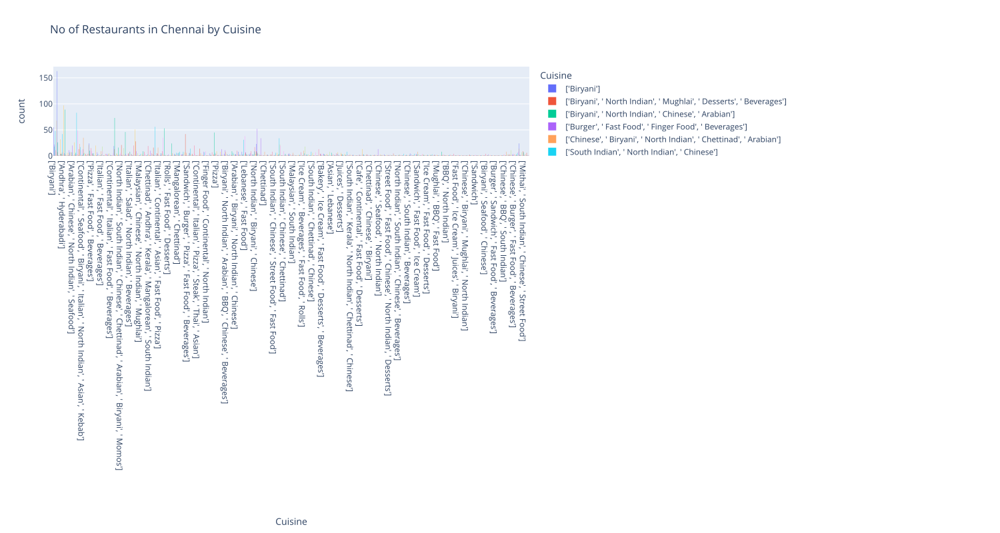

In [54]:
#. How Many types of Cuisine in Chennai resturants?
fig = px.histogram(raw_df,x ="Cuisine", color='Cuisine',
                   title = "No of Restaurants in Chennai by Cuisine")
fig.update_layout(width=1500,height=800)
fig.show()

Resorting to unclean kill browser.


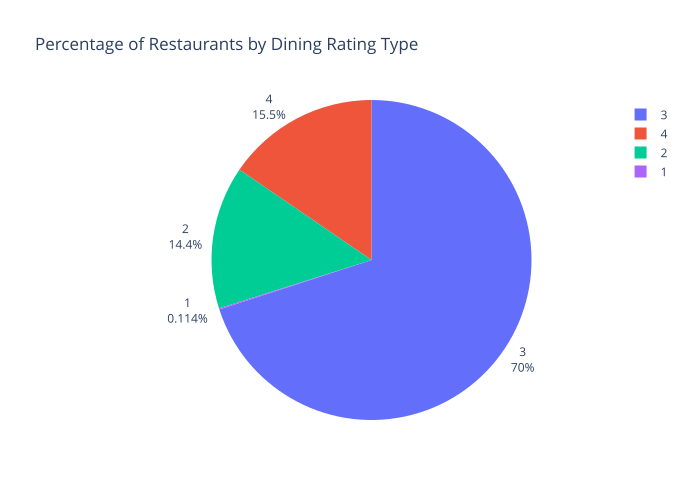

In [57]:
#.Percentage of Restaurants by Dining Rating Type
rating_type_df = raw_df['Dining Rating'].value_counts().reset_index() 
rating_type_df.rename(columns={'index':'Dining Rating', 'RATING_TYPE':'COUNT OF RESTAURANTS'}) 
rating_type_df 

fig = px.pie(
    rating_type_df, 
    names = 'Dining Rating',
    values = 'count', 
    color = 'Dining Rating', 
    title ='Percentage of Restaurants by Dining Rating Type')
fig.update_traces(textposition='outside', textinfo='percent+label')
fig.show()

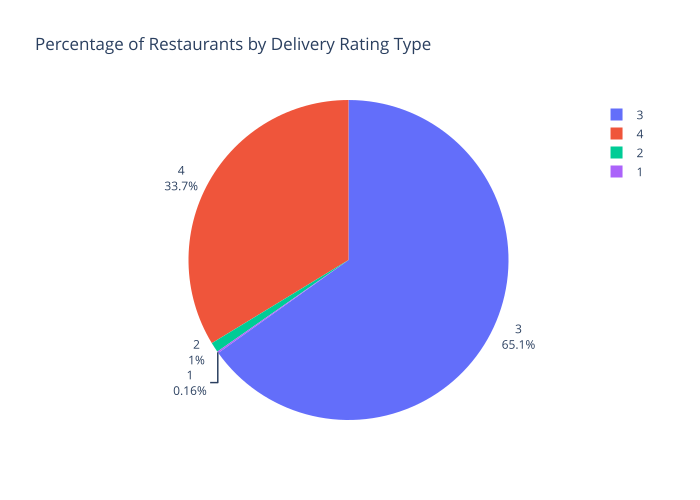

In [58]:
#.Percentage of Restaurants by Delivery Rating Type
rating_type_dr = raw_df['Delivery Rating'].value_counts().reset_index() 
rating_type_dr.rename(columns={'index':'Delivery Rating', 'RATING_TYPE':'COUNT OF RESTAURANTS'}) 
rating_type_dr 

fig = px.pie(
    rating_type_dr, 
    names = 'Delivery Rating',
    values = 'count', 
    color = 'Delivery Rating', 
    title ='Percentage of Restaurants by Delivery Rating Type')
fig.update_traces(textposition='outside', textinfo='percent+label')
fig.show()

In [59]:
#Which are the Top 5 rated Sea Food resturants in chennai?
sea_food_1 = raw_df[raw_df["Cuisine"].str.contains("Seafood")]
sea_food = sea_food_1.sort_values(by="Dining Rating").head(5)
fig = px.histogram(raw_df,x ="Name of Restaurant", y = "Dining Rating", color='Cuisine',
                   title = "Top 5 rated Sea food Restaurants in Chennai")
fig.update_layout(width=1500,height=800)
fig.show()

In [60]:
#. Which is best Food Truck Resturant in chennai
food_truck_1 = raw_df[raw_df["Name of Restaurant"].str.contains("Food Truck")]
food_truck_1.sort_values(by='Dining Rating',ascending=False)


,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features,Home Delivery
687,Chaska Food Truck,Thiruvanmiyur,"['Tibetan', ' Chinese', ' Momos']","['Noodle', ' Schezwan Fried Rice', ' Pan Fried...",250,4,190.0,3,376.0,"['Home Delivery', 'Free Parking', 'Self Servic...",'HomeDelivery'


In [61]:
#. Which Resturants has max delivery rating?
max_delivery = raw_df.groupby(by=["Name of Restaurant","Home Delivery","Location"])["Delivery Rating Count"].max().reset_index()
max_delivery.head()

,Name of Restaurant,Home Delivery,Location,Delivery Rating Count
0,101 Dosa,'HomeDelivery',Velachery,261.0
1,11 O Cafe,'HomeDelivery',Perungudi,67.0
2,186° Celcius,'HomeDelivery',GST Road,279.0
3,196 Degree Below,'HomeDelivery',Alwarpet,107.0
4,24x7 Bytes,,"Gokulam Park Sabari - OMR, Old Mahabalipuram R...",147.0


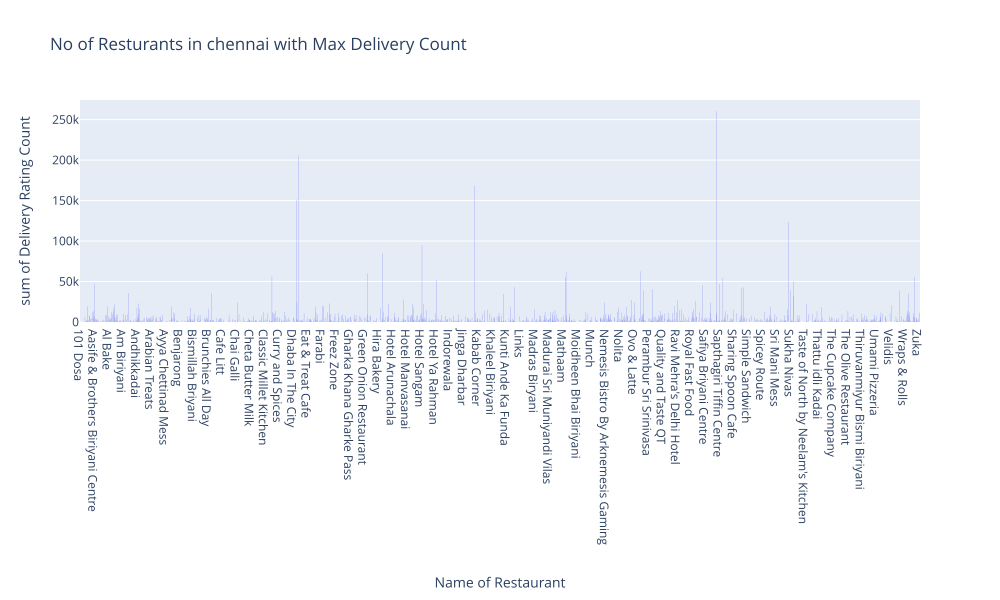

In [62]:
fig = px.histogram(max_delivery,x ="Name of Restaurant", y = "Delivery Rating Count",
                   title = "No of Resturants in chennai with Max Delivery Count")
fig.update_layout(width=1000,height=600)
fig.show()

Resorting to unclean kill browser.


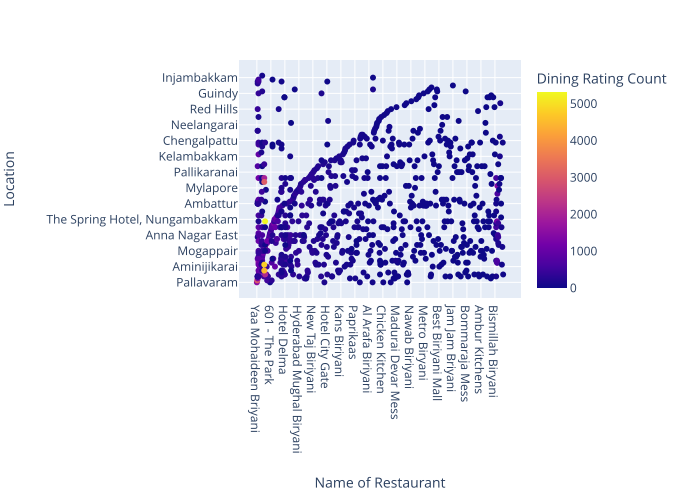

In [73]:
#. whcih is the best biriyani Resturant in Chennai
best_biriyani = raw_df[raw_df['Cuisine'].str.contains('Biryani')]
best_biriyani.sort_values(by='Dining Rating',ascending=False).reset_index()

fig = px.scatter(best_biriyani,x='Name of Restaurant',y='Location',color='Dining Rating Count')
fig.show()


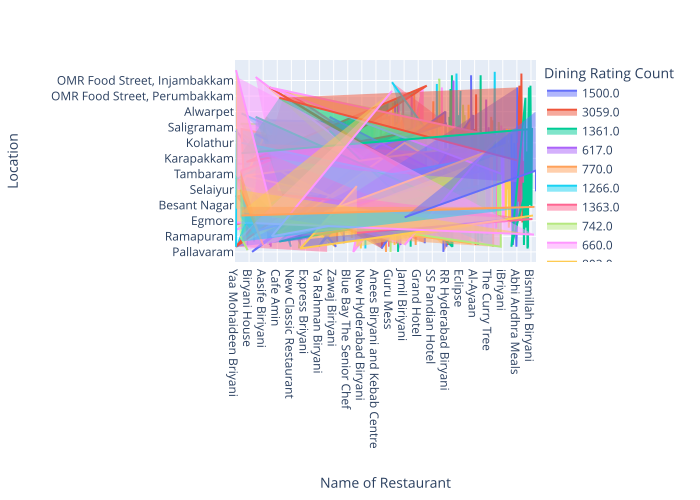

In [74]:
#. whcih is the best biriyani Resturant in Chennai by delivery rating
best_biriyani = raw_df[raw_df['Cuisine'].str.contains('Biryani')]
best_biriyani.sort_values(by='Delivery Rating',ascending=False).reset_index()
fig = px.area(best_biriyani,x='Name of Restaurant',y='Location',color='Dining Rating Count')
fig.show()

In [75]:
#. Which resturants having delivery higest rating above 4
higest_rated_df = raw_df[raw_df["Delivery Rating"] >= 4]
higest_rated_df

,Name of Restaurant,Location,Cuisine,Top Dishes,Price for 2,Dining Rating,Dining Rating Count,Delivery Rating,Delivery Rating Count,Features,Home Delivery
0,Yaa Mohaideen Briyani,Pallavaram,['Biryani'],"['Bread Halwa', ' Chicken 65', ' Mutton Biryan...",500,4,1500.0,4,9306.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
1,Sukkubhai Biriyani,Alandur,"['Biryani', ' North Indian', ' Mughlai', ' Des...","['Beef Biryani', ' Beef Fry', ' Paratha', ' Pa...",1000,4,3059.0,4,39200.0,"['Home Delivery', 'Free Parking', 'Table booki...",'HomeDelivery'
2,SS Hyderabad Biryani,Kodambakkam,"['Biryani', ' North Indian', ' Chinese', ' Ara...","['Brinjal Curry', ' Tandoori Chicken', ' Chick...",500,4,1361.0,4,10500.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
3,KFC,Perambur,"['Burger', ' Fast Food', ' Finger Food', ' Bev...",['Zinger Burger'],500,4,1101.0,4,11200.0,"['Home Delivery', 'Free Parking', 'Card Upon D...",'HomeDelivery'
4,Tasty Kitchen,Perambur,"['Chinese', ' Biryani', ' North Indian', ' Che...","['Mutton Biryani', ' Chicken Rice', ' Tomato R...",450,4,617.0,4,22400.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
...,...,...,...,...,...,...,...,...,...,...,...
4361,Mcrennett,Anna Nagar East,"['Bakery', ' Street Food']",Uncategorized Dish,350,3,28.0,4,69.0,"['Breakfast', 'Home Delivery', 'Indoor Seating...",
4370,Anandhi Idly Kadai,Medavakkam,"['South Indian', ' Chinese']",Uncategorized Dish,200,3,24.0,4,778.0,"['Home Delivery', 'Indoor Seating']",'HomeDelivery'
4371,Anandhi Idly Kadai,Selaiyur,"['South Indian', ' Chinese']",Uncategorized Dish,200,3,17.0,4,367.0,"['Breakfast', 'Home Delivery', 'Indoor Seating']",
4374,Juice World,K.K. Nagar,"['Juices', ' Beverages', ' Sandwich', ' Fast F...",Uncategorized Dish,300,3,10.0,4,97.0,"['Home Delivery', 'Vegetarian Only', 'Indoor S...",'HomeDelivery'


Resorting to unclean kill browser.


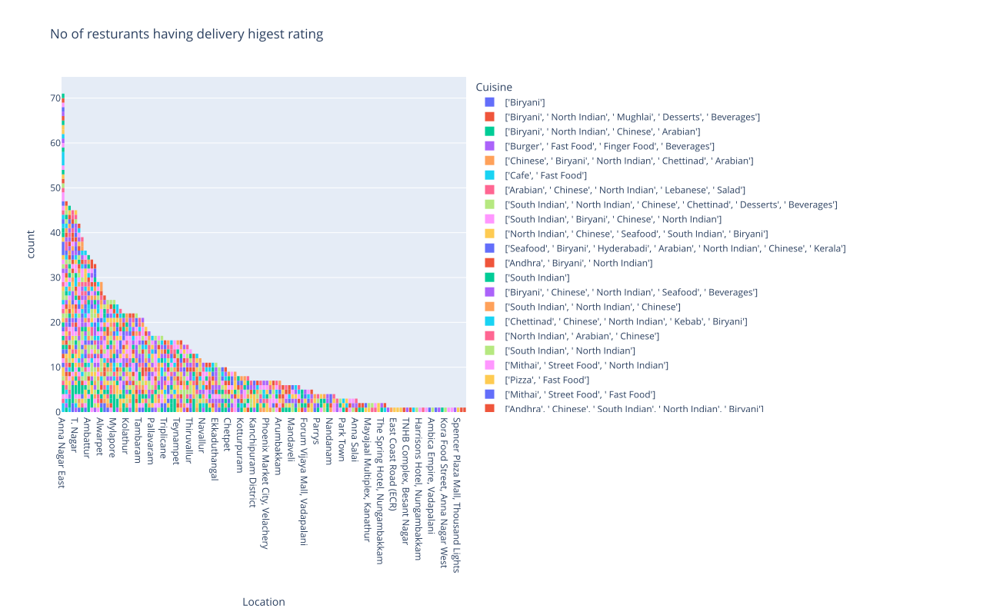

In [76]:
fig = px.histogram(higest_rated_df,x ="Location",color='Cuisine',
                   title = "No of resturants having delivery higest rating").update_xaxes(categoryorder="total descending")
fig.update_layout(width=1300,height=800)
fig.show()